In [1]:
# Chargement libraries et data
import io
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci
from scipy.io import loadmat
from scipy.signal import hilbert
from scipy.stats import kurtosis
from scipy.fftpack import fft, fftfreq

# ------------------------------------------------------------------
# 1.1 Les numéros de fichiers du site, page par page
#     clé = (défaut, diamètre en millièmes de pouce)
#     valeur = numéros pour les charges 0, 1, 2, 3 HP (None = absent)
# ------------------------------------------------------------------
NORMAL = [97, 98, 99, 100]

PAGES = {
    "12kDE": (12000, {
        ("IR", 7): [105, 106, 107, 108],      ("B", 7): [118, 119, 120, 121],
        ("OR@6", 7): [130, 131, 132, 133],    ("OR@3", 7): [144, 145, 146, 147],
        ("OR@12", 7): [156, 158, 159, 160],
        ("IR", 14): [169, 170, 171, 172],     ("B", 14): [185, 186, 187, 188],
        ("OR@6", 14): [197, 198, 199, 200],
        ("IR", 21): [209, 210, 211, 212],     ("B", 21): [222, 223, 224, 225],
        ("OR@6", 21): [234, 235, 236, 237],   ("OR@3", 21): [246, 247, 248, 249],
        ("OR@12", 21): [258, 259, 260, 261],
        ("IR", 28): [3001, 3002, 3003, 3004], ("B", 28): [3005, 3006, 3007, 3008],
    }),
    "48kDE": (48000, {
        ("IR", 7): [109, 110, 111, 112],      ("B", 7): [122, 123, 124, 125],
        ("OR@6", 7): [135, 136, 137, 138],    ("OR@3", 7): [148, 149, 150, 151],
        ("OR@12", 7): [161, 162, 163, 164],
        ("IR", 14): [174, 175, 176, 177],     ("B", 14): [189, 190, 191, 192],
        ("OR@6", 14): [201, 202, 203, 204],
        ("IR", 21): [213, 214, 215, 217],     ("B", 21): [226, 227, 228, 229],
        ("OR@6", 21): [238, 239, 240, 241],   ("OR@3", 21): [250, 251, 252, 253],
        ("OR@12", 21): [262, 263, 264, 265],
    }),
    "12kFE": (12000, {
        ("IR", 7): [278, 279, 280, 281],      ("B", 7): [282, 283, 284, 285],
        ("OR@6", 7): [294, 295, 296, 297],    ("OR@3", 7): [298, 299, 300, 301],
        ("OR@12", 7): [302, 305, 306, 307],
        ("IR", 14): [274, 275, 276, 277],     ("B", 14): [286, 287, 288, 289],
        ("OR@6", 14): [313, None, None, None], ("OR@3", 14): [310, 309, 311, 312],
        ("IR", 21): [270, 271, 272, 273],     ("B", 21): [290, 291, 292, 293],
        ("OR@6", 21): [315, None, None, None], ("OR@3", 21): [None, 316, 317, 318],
    }),
}

RPM_NOMINAL = {0: 1797, 1: 1772, 2: 1750, 3: 1730}

# ------------------------------------------------------------------
# 1.2 Le catalogue : une ligne par fichier, avec un nom lisible
#     ex. 'Normal_L0', '12kDE_IR007_L0', '12kDE_OR021at3_L2', '48kDE_B014_L1'
# ------------------------------------------------------------------
lignes = []
for charge, num in enumerate(NORMAL):
    lignes.append({"nom": f"Normal_L{charge}", "numero": num, "source": "Normal",
                   "fs": 12000, "defaut": "Sain", "position_OR": None,
                   "diametre_mils": 0, "charge_hp": charge})

for source, (fs, table) in PAGES.items():
    for (defaut, diametre), numeros in table.items():
        localisation, _, position = defaut.partition("@")
        for charge, num in enumerate(numeros):
            if num is None:
                continue
            nom = f"{source}_{localisation}{diametre:03d}" + (f"at{position}" if position else "") + f"_L{charge}"
            lignes.append({"nom": nom, "numero": num, "source": source, "fs": fs,
                           "defaut": localisation, "position_OR": position or None,
                           "diametre_mils": diametre, "charge_hp": charge})

catalogue = pd.DataFrame(lignes).set_index("nom")
catalogue["rpm_nominal"] = catalogue["charge_hp"].map(RPM_NOMINAL)

# ------------------------------------------------------------------
# 1.3 Lecture d'un fichier depuis le site (copie locale sous un nom lisible)
# ------------------------------------------------------------------
URL_CWRU = "https://engineering.case.edu/sites/default/files/"
CACHE = Path("../data/cwru_cache")

def charger(nom):
    """Renvoie {'DE', 'FE', 'BA', 'fs', 'rpm'} pour un fichier du catalogue
    (ex. '12kDE_IR007_L0')."""
    info = catalogue.loc[nom]
    numero = int(info["numero"])
    chemin = CACHE / f"{nom}__{numero}.mat"            # ex. 12kDE_IR007_L0__105.mat

    if not chemin.exists():                            # 1re fois : téléchargement depuis le site
        CACHE.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(URL_CWRU + f"{numero}.mat") as reponse:
            chemin.write_bytes(reponse.read())
    mat = loadmat(chemin)

    def choisir(suffixe):                              # privilégie la variable du bon numéro
        cles = [k for k in mat if k.endswith(suffixe)]
        bonne = [k for k in cles if k.startswith(f"X{numero:03d}")]
        return (bonne or cles or [None])[0]

    signaux = {"fs": int(info["fs"])}
    for canal in ["DE", "FE", "BA"]:
        cle = choisir(f"_{canal}_time")
        signaux[canal] = None if cle is None else np.ravel(mat[cle])
    cle_rpm = choisir("RPM")
    signaux["rpm"] = float(np.squeeze(mat[cle_rpm])) if cle_rpm else float(info["rpm_nominal"])
    return signaux

from IPython.display import Markdown

tab = catalogue.groupby(["source", "defaut"]).size().unstack(fill_value=0)
tab = tab[["Sain", "IR", "B", "OR"]].reindex(["Normal", "12kDE", "48kDE", "12kFE"])
tab = tab.reset_index().rename(columns={"source": "Source", "IR": "Bague int. (IR)",
                                        "B": "Bille (B)", "OR": "Bague ext. (OR)"})
# Markdown(tab.to_markdown(index=False))

In [2]:
# Définitions fonctions
def spectre_fft(x, fs):
    """Spectre d'amplitude : renvoie (fréquences, amplitudes)."""
    n = len(x)
    freqs = fftfreq(n, d=1 / fs)[: n // 2]
    amp = np.abs(fft(x - np.mean(x)))[: n // 2] * 2 / n # ajout de "- np.mean(x)" pour supprimer la composante continue du signal
    return freqs, amp

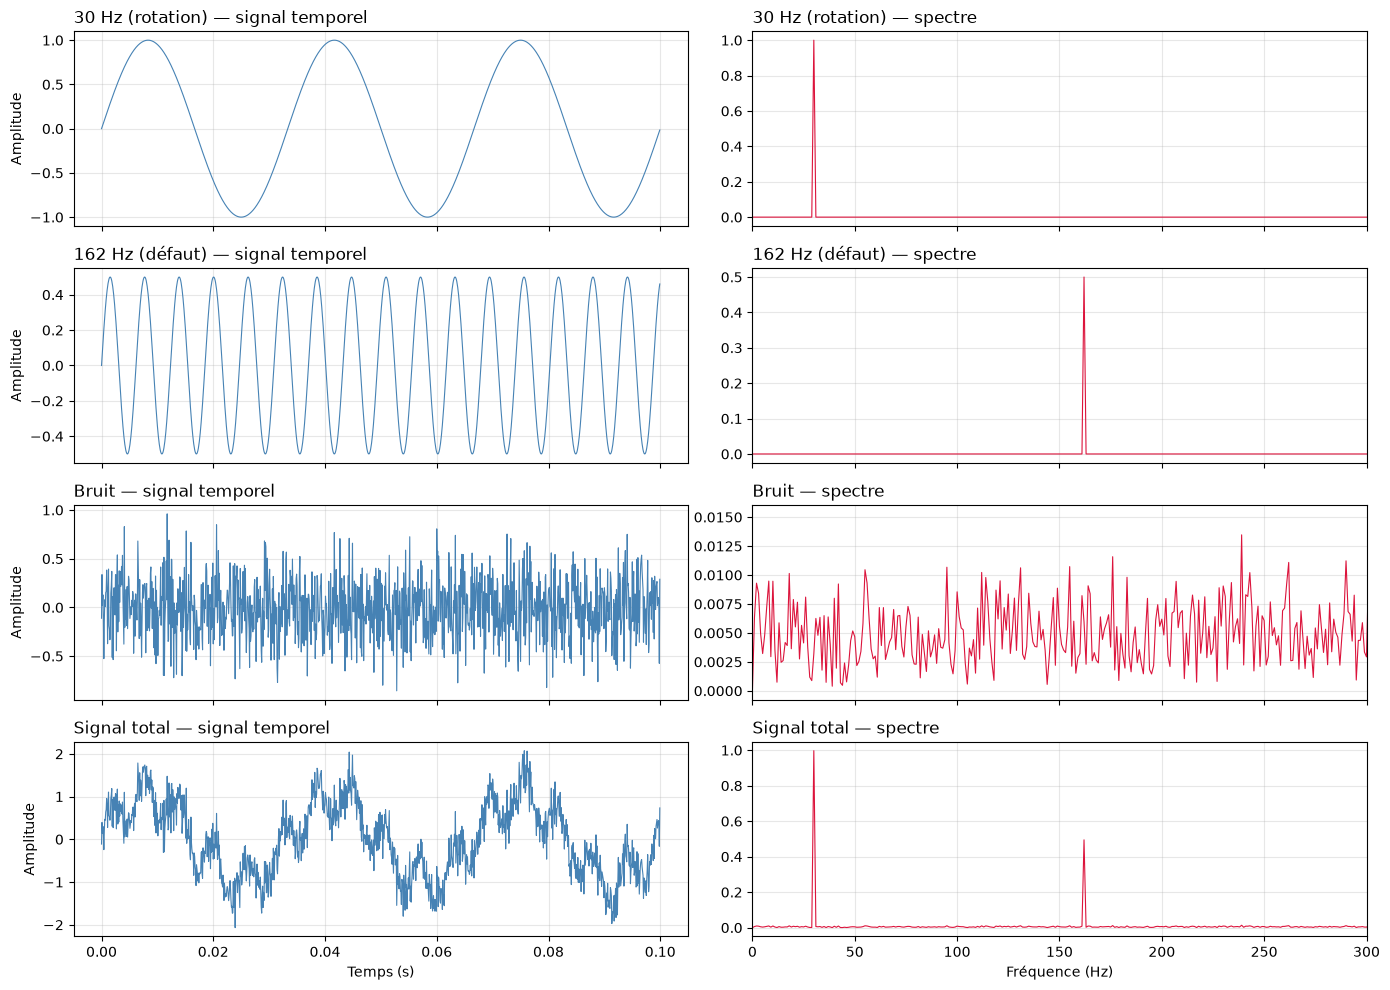

In [3]:
#  fig-cap: "Décomposition d'un signal synthétique : composantes temporelles (gauche) et spectrales (droite)."

fs = 12_000
t = np.arange(0, 1, 1 / fs)
x30hz = 1.0 * np.sin(2 * np.pi * 30 * t)      # "rotation" à 30 Hz
x162hz = 0.5 * np.sin(2 * np.pi * 162 * t)    # "défaut" à 162 Hz
xbruit = 0.3 * np.random.randn(len(t))        # bruit 
xtot = x30hz + x162hz + xbruit

# --- Calcul des spectres (une seule fois par composante) ---
f_30hz, a30 = spectre_fft(x30hz, fs)
f_162hz, a162 = spectre_fft(x162hz, fs)
f_bruit, a_bruit = spectre_fft(xbruit, fs)
f_tot, a_tot = spectre_fft(xtot, fs)

fig, axes = plt.subplots(4, 2, figsize=(14, 10), sharex="col")

# Colonne 0 : signaux temporels — Colonne 1 : spectres
signaux = [
    (x30hz,  f_30hz,  a30,     "30 Hz (rotation)"),
    (x162hz, f_162hz, a162,    "162 Hz (défaut)"),
    (xbruit, f_bruit, a_bruit, "Bruit"),
    (xtot,   f_tot,   a_tot,   "Signal total"),
]
n = int(0.1 * fs)   # 0,1 seconde

for ligne, (x, freqs, amp, titre) in enumerate(signaux):
    # --- Colonne 0 : temporel ---
    axes[ligne, 0].plot(t[:n], x[:n], color="steelblue", lw=0.8)
    axes[ligne, 0].set_title(f"{titre} — signal temporel", loc="left")
    axes[ligne, 0].set_ylabel("Amplitude")
    axes[ligne, 0].grid(alpha=0.3)

    # --- Colonne 1 : spectre, zoomé sur 0–300 Hz ---
    axes[ligne, 1].plot(freqs, amp, color="crimson", lw=0.8)
    axes[ligne, 1].set_xlim(0, 300)
    axes[ligne, 1].set_title(f"{titre} — spectre", loc="left")
    axes[ligne, 1].grid(alpha=0.3)

axes[-1, 0].set_xlabel("Temps (s)")
axes[-1, 1].set_xlabel("Fréquence (Hz)")
plt.tight_layout(); plt.show()

Dans le signal temporel, on devine une ondulation brouillée. Dans le spectre, on peut voir deux pics nets, à 30 et 162 Hz, la hauteur du premier étant environ le double du second. C’est exactement ce que nous avions mis dans le signal.

In [4]:
NOM_SAIN   = "Normal_L0"
NOM_DEFAUT = "12kDE_IR007_L0"

sain   = charger(NOM_SAIN)
defaut = charger(NOM_DEFAUT)

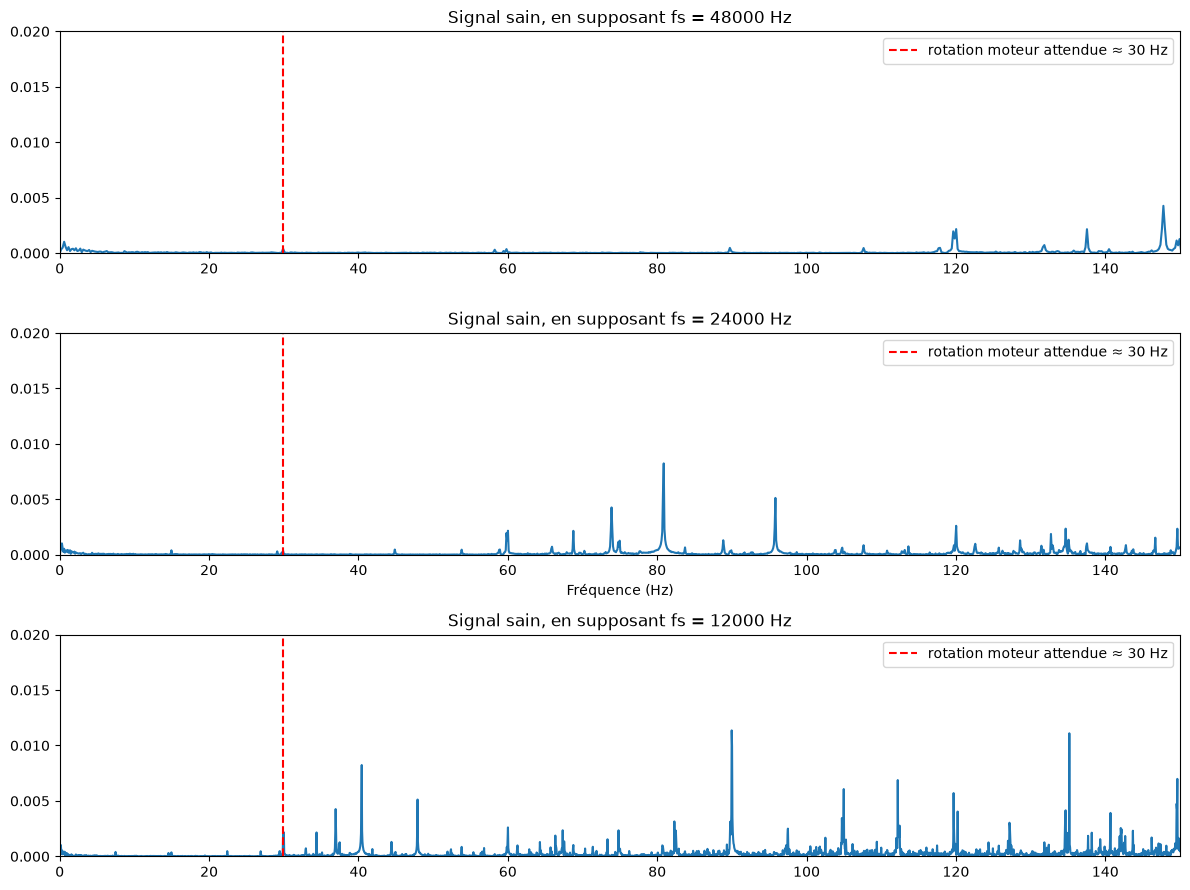

In [5]:
x = sain["DE"]  # signal du capteur DE (Drive End)
fig, axes = plt.subplots(3, 1, figsize=(12, 9))
for ax, fs in zip(axes, [48000, 24000, 12000]):
    f, a = spectre_fft(x, fs)
    ax.plot(f, a)
    ax.set_xlim(0, 150)
    ax.set_ylim(0, 0.02)
    ax.axvline(1797/60, color="red", ls="--", label="rotation moteur attendue ≈ 30 Hz")
    ax.set_title(f"Signal sain, en supposant fs = {fs} Hz")
    ax.legend()
axes[1].set_xlabel("Fréquence (Hz)")
plt.tight_layout(); plt.show()

In [6]:
f_rot = 1797 / 60                # rotation de l'arbre ≈ 30 Hz

freqs_def = {
    "Rotation (1×)": f_rot,
    "BPFO (bague ext.)": 3.5848 * f_rot,
    "BSF (bille)": 4.7135 * f_rot,
    "BPFI (bague int.)": 5.4152 * f_rot,
}
for nom, f in freqs_def.items():
    print(f"{nom:20s} {f:6.1f} Hz")

Rotation (1×)          29.9 Hz
BPFO (bague ext.)     107.4 Hz
BSF (bille)           141.2 Hz
BPFI (bague int.)     162.2 Hz


- BPFO : fréquence de passage des billes sur un défaut de la bague extérieure, soit environ 107 Hz.
- BSF : fréquence de rotation de la bille sur elle-même, soit environ 141 Hz. Un défaut de bille frappe souvent deux fois par tour de bille, donc on le cherche aussi vers 2 × BSF ≈ 282 Hz.
- BPFI : fréquence de passage des billes sur un défaut de la bague intérieure, soit environ 162 Hz. C’est celle que déjà repérée à l’œil.

AttributeError: 'list' object has no attribute 'items'

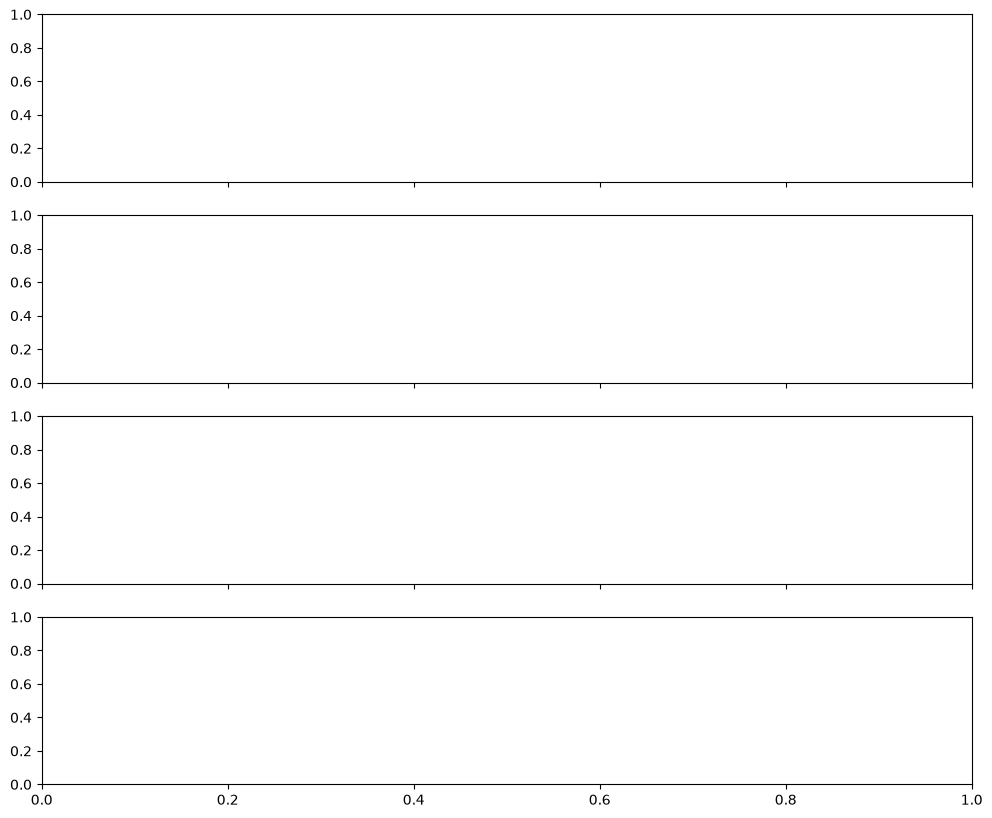

In [7]:
fs = 12000
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True, sharey=True)
for ax, (nom, x) in zip(axes, signaux.items()):
    f, a = spectre(x, fs)
    ax.plot(f, a, lw=0.6)
    ax.set_title(nom, loc="left")
    ax.set_yscale("log")
axes[-1].set_xlabel("Fréquence (Hz)")
plt.tight_layout(); plt.show()

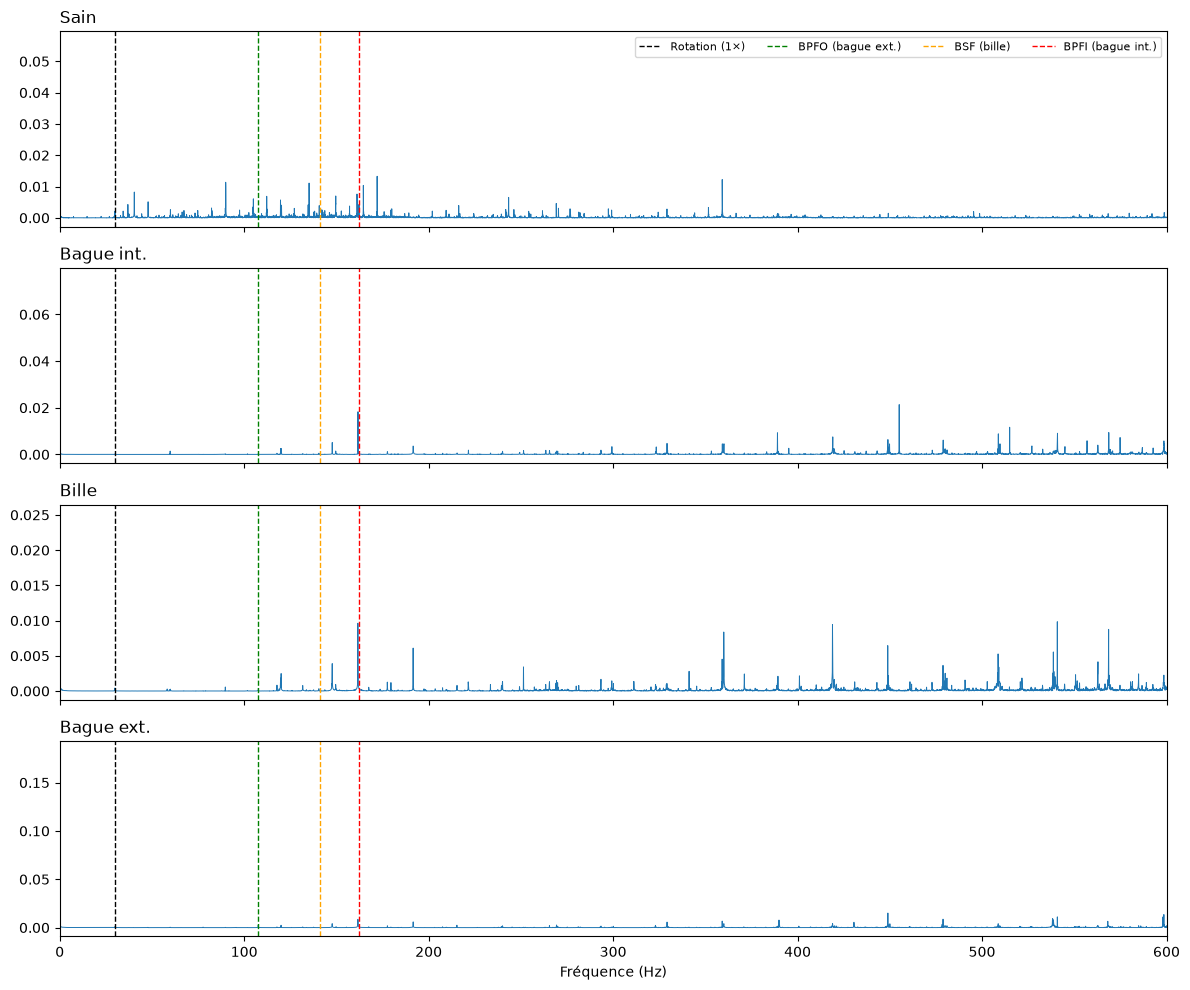

In [ ]:
couleurs = ["black", "green", "orange", "red"]
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, (nom, x) in zip(axes, signaux.items()):
    f, a = spectre(x, fs)
    ax.plot(f, a, lw=0.7)
    for (lab, fd), c in zip(freqs_def.items(), couleurs):
        ax.axvline(fd, color=c, ls="--", lw=1, label=lab)
    ax.set_xlim(0, 600)
    ax.set_title(nom, loc="left")
axes[0].legend(fontsize=8, ncol=4)
axes[-1].set_xlabel("Fréquence (Hz)")
plt.tight_layout(); plt.show()

On voit sur le graphe que les défaults ajoutent le plus d'énerngie par rapport au sain en hautes fréquences. 

In [ ]:
n, d, D = 9, 0.3126, 1.537
r = d / D

FTF  = 0.5 * (1 - r)
BPFO = n * FTF
BPFI = n * (1 - FTF)
BSF  = (D / (2*d)) * (1 - r**2)

print(f"FTF={FTF:.4f}  BPFO={BPFO:.4f}  BPFI={BPFI:.4f}  BSF={BSF:.4f}  2×BSF={2*BSF:.4f}")

FTF=0.3983  BPFO=3.5848  BPFI=5.4152  BSF=2.3567  2×BSF=4.7134


Le roulement côté entraînement : SKF 6205

9 billes ;
diamètre d’une bille : d = 0,3126 pouce ;
diamètre moyen du roulement, mesuré au centre des billes : D = 1,537 pouce ;
la bague intérieure tourne avec l’arbre, et la bague extérieure est fixe.

Le seul rapport qui compte est d/D = 0,3126 / 1,537 ≈ 0,2034.

Le raisonnement

1. La cage tourne moins vite que l’arbre. Les billes roulent entre une bague qui tourne et une bague fixe, un peu comme un rouleau coincé entre une planche qu’on pousse et le sol : il avance moins vite que la planche. La cage, avec les billes, tourne donc à :

FTF = ½ × (1 − d/D) = ½ × (1 − 0,2034) ≈ 0,398 × la vitesse de l’arbre

2. Défaut sur la bague extérieure (BPFO). Cette bague est fixe, donc les 9 billes défilent sur le défaut à la vitesse de la cage :

BPFO = 9 × 0,398 ≈ 3,5848

3. Défaut sur la bague intérieure (BPFI). Cette bague tourne à la vitesse 1, et la cage à 0,398, dans le même sens. Leur vitesse relative vaut 1 − 0,398 = 0,602, et 9 billes défilent sur le défaut à cette vitesse :

BPFI = 9 × 0,602 ≈ 5,4152

C’est pourquoi le défaut de bague intérieure produit des chocs plus fréquents que celui de bague extérieure.

4. Défaut sur une bille. La bille tourne sur elle-même à :

BSF = (D / 2d) × (1 − (d/D)²) ≈ 2,357

Mais à chaque tour sur elle-même, le défaut touche les deux bagues, l’intérieure puis l’extérieure. Le rythme des chocs vaut donc 2 × 2,357 = 4,7135.

le chiffre 4,7135 du site CWRU inclut déjà ce facteur 2. Le pic du défaut de bille est donc à chercher vers 141 Hz, et non à 282 Hz. La vraie rotation de la bille sur elle-même est à environ 71 Hz.

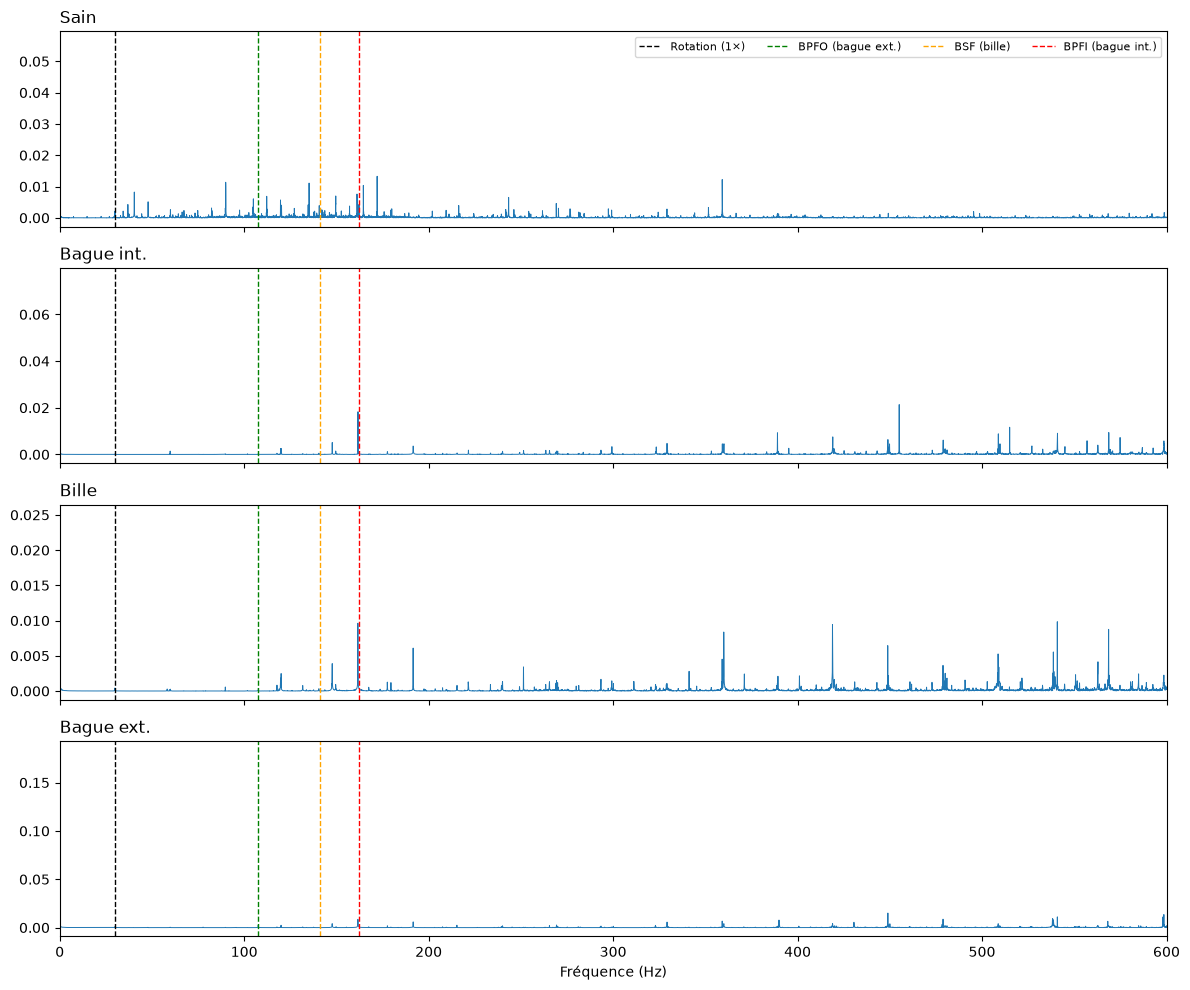

In [ ]:
couleurs = ["black", "green", "orange", "red"]
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, (nom, x) in zip(axes, signaux.items()):
    f, a = spectre(x, fs)
    ax.plot(f, a, lw=0.7)
    for (lab, fd), c in zip(freqs_def.items(), couleurs):
        ax.axvline(fd, color=c, ls="--", lw=1, label=lab)
    ax.set_xlim(0, 600)
    ax.set_title(nom, loc="left")
axes[0].legend(fontsize=8, ncol=4)
axes[-1].set_xlabel("Fréquence (Hz)")
plt.tight_layout(); plt.show()

Pour les billes et bague extérieur le pic est visiblement moins aligné sur la fréquence théorique contrairement à sain et bague intérieur. 
Pourquoi les pics des défauts sont-ils peu visibles ? Reprenons la cloche. Si on la frappe 162 fois par seconde, on entend le son de la cloche, aigu, vers 3 000 Hz. Le chiffre 162 n’est pas un son : c’est le rythme des coups. Le spectre classique montre les « sons », donc la résonance, mais pas bien le rythme. Or c’est le rythme qui dit quel élément est défectueux.

L’analyse d’enveloppe : retrouver le rythme des chocs

Elle se fait en trois étapes :

1. Filtrer le signal pour ne garder que la zone de résonance, là où les défauts ajoutent de l’énergie. On élimine ainsi la rotation et les autres vibrations de la machine.
2. Calculer l’enveloppe, c’est-à-dire tracer le contour supérieur des bouffées, comme si on reliait le sommet de chaque paquet d’oscillations. On obtient une courbe qui monte à chaque choc et redescend entre deux chocs.
3. Faire la FFT de cette enveloppe. Puisqu’elle bat au rythme des chocs, son spectre montre un pic à la fréquence du défaut.

In [ ]:
from scipy.signal import butter, filtfilt, hilbert

def enveloppe(x, fs, f_bas=2000, f_haut=5000):
    b, a = butter(4, [f_bas, f_haut], btype="bandpass", fs=fs)   # 1. filtre passe-bande
    x_filt = filtfilt(b, a, x)
    env = np.abs(hilbert(x_filt))                                 # 2. contour des bouffées
    return x_filt, env - env.mean()                               # on retire la moyenne

- butter et filtfilt gardent uniquement les fréquences entre 2 00 et 600 Hz. la zone où on a vu l’énergie des défauts.
- hilbert est l’outil mathématique qui calcule l’enveloppe. 
- On retire la moyenne pour éviter un pic géant à 0 Hz qui écraserait le reste.

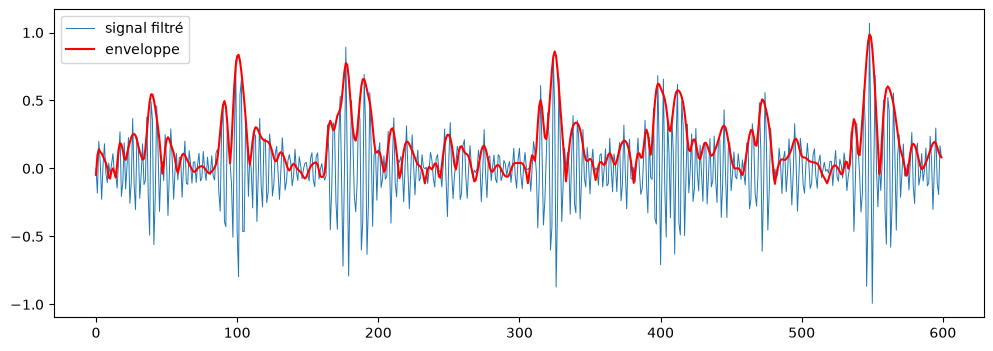

In [ ]:
fs = 12000
x = signaux["Bague int."]
x_filt, env = enveloppe(x, fs)
n = 600   # 0,05 s
plt.figure(figsize=(12, 4))
plt.plot(x_filt[:n], lw=0.7, label="signal filtré")
plt.plot(env[:n] + np.abs(env).mean(), color="red", lw=1.5, label="enveloppe")
plt.legend(); plt.show()

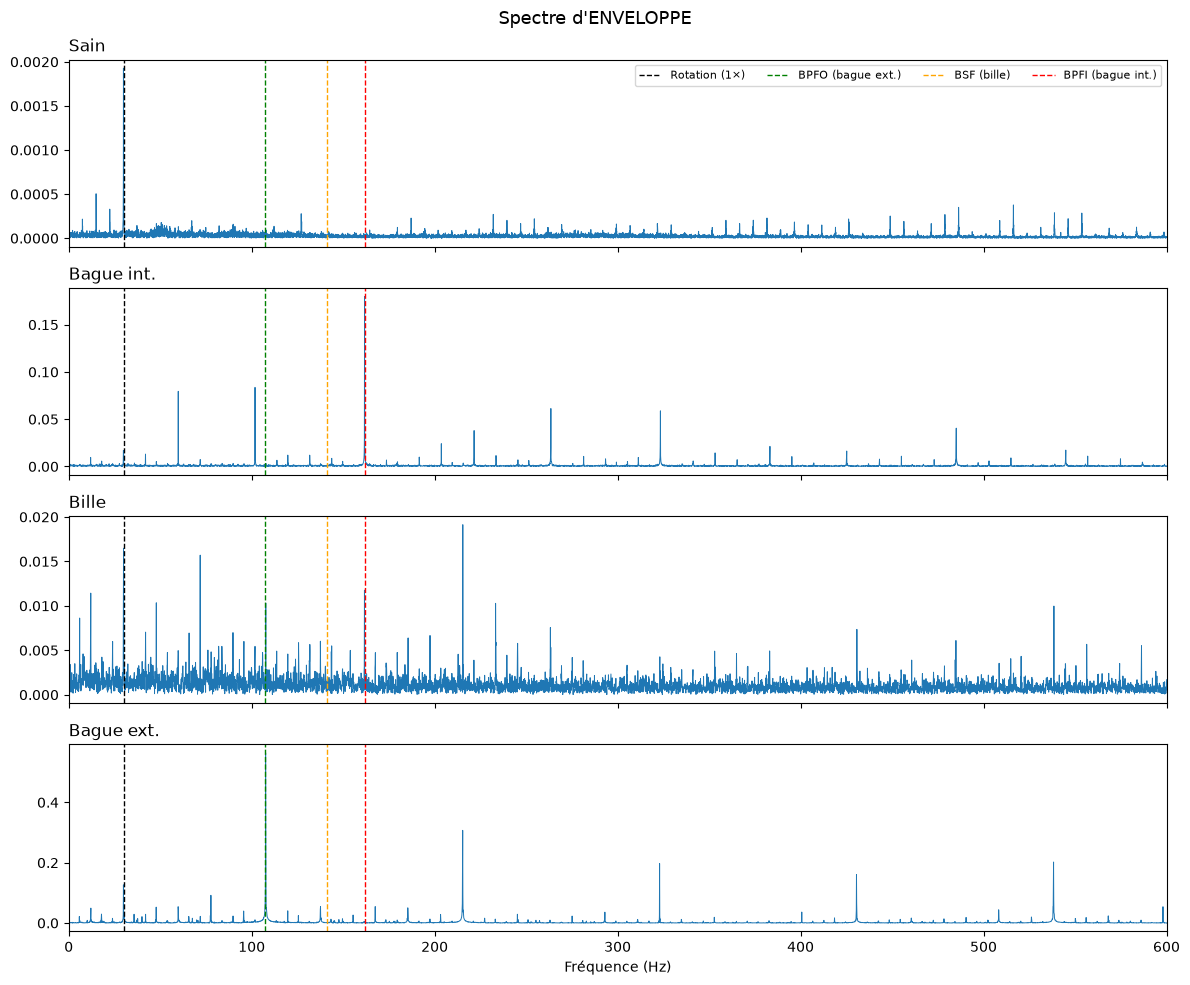

In [ ]:
fs = 12000

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, (nom, x) in zip(axes, signaux.items()):
    _, env = enveloppe(x, fs)          # 1. on calcule l'enveloppe
    f, a = spectre(env, fs)            # 2. on fait la FFT de l'ENVELOPPE
    ax.plot(f, a, lw=0.7)
    for (lab, fd), c in zip(freqs_def.items(), couleurs):
        ax.axvline(fd, color=c, ls="--", lw=1, label=lab)
    ax.set_xlim(0, 600)
    ax.set_title(nom, loc="left")
axes[0].legend(fontsize=8, ncol=4)
axes[-1].set_xlabel("Fréquence (Hz)")
fig.suptitle("Spectre d'ENVELOPPE", fontsize=13)
plt.tight_layout(); plt.show()

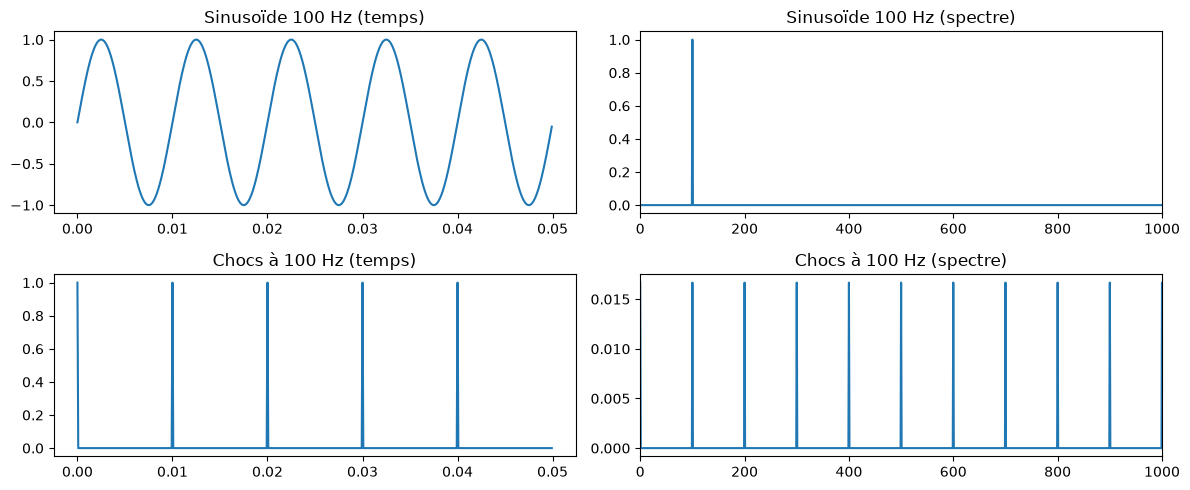

In [ ]:
fs = 12000
t = np.arange(0, 1, 1/fs)
sinus = np.sin(2*np.pi*100*t)                        # vibration lisse à 100 Hz
chocs = np.zeros_like(t); chocs[::fs//100] = 1       # un choc bref toutes les 1/100 s

fig, axes = plt.subplots(2, 2, figsize=(12, 5))
for i, (nom, x) in enumerate([("Sinusoïde 100 Hz", sinus), ("Chocs à 100 Hz", chocs)]):
    axes[i, 0].plot(t[:600], x[:600]); axes[i, 0].set_title(nom + " (temps)")
    f, a = spectre(x, fs)
    axes[i, 1].plot(f, a); axes[i, 1].set_xlim(0, 1000); axes[i, 1].set_title(nom + " (spectre)")
plt.tight_layout(); plt.show()

In [ ]:
import numpy as np

fs = 1000            # fréquence d'échantillonnage (Hz)
N  = 1000            # nb d'échantillons → T = 1 s, résolution Δf = 1 Hz
t  = np.arange(N) / fs

# signal : moyenne 0.5 + 3·cos(50 Hz) + 1·sin(120 Hz)
x = 0.5 + 3*np.cos(2*np.pi*50*t) + 1*np.sin(2*np.pi*120*t)

X = np.fft.rfft(x)                  # N//2 + 1 = 501 valeurs complexes
f = np.fft.rfftfreq(N, d=1/fs)      # 0, 1, 2, ..., 500 Hz

A = np.abs(X) / N
A[1:-1] *= 2                        # facteur 2 sauf DC et Nyquist (N pair)

for fk in (0, 50, 120):
    k = np.argmin(np.abs(f - fk))
    print(f"{f[k]:>5.0f} Hz  amplitude={A[k]:.3f}  phase={np.angle(X[k]):+.3f} rad")

# Vérification "à la main" de la formule de la DFT pour k = 50
k = 50
X50_manuel = np.sum(x * np.exp(-2j*np.pi*k*np.arange(N)/N))
print(np.allclose(X50_manuel, X[k]))   # True

# Reconstruction exacte
print(np.allclose(np.fft.irfft(X, n=N), x))  # True

    0 Hz  amplitude=0.500  phase=+0.000 rad
   50 Hz  amplitude=3.000  phase=+0.000 rad
  120 Hz  amplitude=1.000  phase=-1.571 rad
True
True
